# Regressão logística do zero — múltiplas entradas e comparação com scikit-learn

Este notebook desenvolve a regressão logística a partir das fórmulas e implementa suas operações em NumPy: separação dos dados, padronização, sigmoide, gradiente, treinamento e previsão. A leitura do **CSV continua com pandas**, usando as **30 características**.

O modelo manual e o scikit-learn recebem os mesmos dados preparados com NumPy e usam o mesmo objetivo **sem regularização**. A comparação considera probabilidades, acurácia e tipos de erro.

**Alvo:** `0 = benigno (B)` e `1 = maligno (M)`. Classificamos amostras já coletadas a partir de medidas celulares; não estimamos risco futuro de desenvolver câncer.

**Execução:** mantenha `breast-cancer.csv` nesta pasta, selecione o Python de `venv` e execute as células de cima para baixo. As explicações detalham cada linha e a origem das fórmulas. Os resultados e os dois gráficos ficam salvos no notebook.

## 1. Importações

Pandas lê e organiza a tabela; NumPy realiza as operações numéricas e a preparação dos dados; Matplotlib desenha os gráficos. Do scikit-learn, usamos a acurácia como métrica pronta e a regressão logística como implementação de referência.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression

**Explicação linha a linha**

1. NumPy fornece vetores, matrizes, sorteio de índices e operações matemáticas; o apelido será `np`.
2. Pandas lê o CSV e organiza tabelas; o apelido será `pd`.
3. Matplotlib desenha os dois gráficos; o apelido será `plt`.
4. `accuracy_score` calcula a fração de decisões corretas. É uma métrica, não uma etapa de preparação ou treinamento.
5. `LogisticRegression` será a implementação de referência.

A separação e a padronização serão feitas com NumPy. Não importamos um carregador de base: a fonte dos dados é o CSV local.

## 2. Ler o CSV e separar as 30 entradas da resposta

Uma linha corresponde a uma amostra. `diagnosis` é a resposta conhecida. `id` é um identificador, e `Unnamed: 32` é uma coluna vazia deste arquivo. As outras 30 colunas são medidas celulares.

In [2]:
dados = pd.read_csv("breast-cancer.csv")
X = dados.drop(columns=["id", "diagnosis", "Unnamed: 32"]).to_numpy()
y = dados["diagnosis"].map({"B": 0, "M": 1}).to_numpy()
print("X:", X.shape, "| y:", y.shape)
print(dados["diagnosis"].value_counts())
dados.head()

X: (569, 30) | y: (569,)
diagnosis
B    357
M    212
Name: count, dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


**Explicação linha a linha**

1. `read_csv` lê o arquivo em um DataFrame. Relendo o original nesta célula, mantemos as letras B/M disponíveis para repetir a conversão.
2. `drop` remove o identificador, a resposta e a coluna vazia. `to_numpy` transforma as medidas em uma matriz numérica: **569 amostras × 30 entradas**.
3. `map` traduz B para 0 e M para 1; `to_numpy` produz um vetor de 569 respostas. A resposta não é colocada dentro das entradas.
4. `shape` mostra as dimensões de cada objeto.
5. `value_counts` mostra 357 benignos e 212 malignos.
6. `head()` exibe as primeiras cinco linhas, pois é a última expressão da célula.

A conversão não sobrescreve `dados["diagnosis"]`: reexecutar não compara números com a letra M e não zera todos os rótulos.

## 3. Separar treino e teste com NumPy

O treino será usado para aprender os parâmetros; o teste será reservado para avaliar amostras que não participaram do ajuste. Se avaliássemos apenas as mesmas amostras usadas para aprender, não mediríamos o desempenho em observações separadas.

Embaralhamos os índices das linhas e reservamos aproximadamente 80% para treino. Com $N$ amostras, o ponto de corte é:

$$k=\lfloor 0{,}8N\rfloor.$$

Os primeiros $k$ índices sorteados vão para o treino e os restantes para o teste. Aplicar os mesmos índices a `X` e `y` preserva a correspondência entre medidas e respostas. Sortear **índices sem repetição** garante que uma mesma linha não apareça nos dois conjuntos.

Usamos uma divisão aleatória simples, sem estratificação: as proporções das classes podem diferir um pouco entre os conjuntos. A semente fixa permite reproduzir a mesma divisão com esta base e este gerador. Como o procedimento mudou, o sorteio não é o mesmo da versão que usava scikit-learn.

In [3]:
rng = np.random.default_rng(42)
indices = rng.permutation(len(y))
cut = int(0.8 * len(y))
train_indices = indices[:cut]
test_indices = indices[cut:]
X_train, X_test = X[train_indices], X[test_indices]
y_train, y_test = y[train_indices], y[test_indices]
print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Treino: (455, 30) | Teste: (114, 30)


**Explicação linha a linha**

1. `default_rng(42)` cria um gerador de números aleatórios com semente fixa. Criá-lo nesta célula permite repetir a mesma divisão ao reexecutá-la.
2. `len(y)` é o número de respostas. `permutation` embaralha todos os índices de 0 a 568 sem repetir nenhum.
3. `int(0.8 * len(y))` calcula o tamanho do treino. Como o valor é positivo, a conversão para inteiro descarta a parte decimal: 455 linhas.
4. `indices[:cut]` seleciona o primeiro bloco de índices sorteados.
5. `indices[cut:]` seleciona o bloco restante: 114 linhas de teste. Os blocos não se sobrepõem.
6. A indexação por vetores de inteiros seleciona as linhas de `X` para cada conjunto.
7. Os mesmos índices selecionam as respostas em `y`. Embaralhar entradas e respostas independentemente destruiria os pares corretos.
8. Mostramos os formatos: `(455, 30)` no treino e `(114, 30)` no teste.

O sorteio acontece antes de calcular médias, desvios ou pesos. O teste não será usado para escolher o número de passos, a taxa de aprendizado ou o limiar.

## 4. Padronizar com NumPy

As características têm unidades e magnitudes diferentes: área, raio e suavidade não variam na mesma escala. Na descida do gradiente, essas diferenças podem produzir direções com sensibilidades muito distintas, dificultando a escolha de uma taxa de aprendizado comum. A padronização ajuda a otimização; não é uma etapa que aprende o diagnóstico.

Aqui, “normalizar” significa **padronizar por média e desvio padrão**. Não estamos colocando os dados no intervalo de 0 a 1.

Para cada característica $j$, calculamos no treino:

$$\mu_j=\frac{1}{m}\sum_{i=1}^{m}x_{ij},\qquad s_j=\sqrt{\frac{1}{m}\sum_{i=1}^{m}(x_{ij}-\mu_j)^2}.$$

Depois transformamos cada valor:

$$x'_{ij}=\frac{x_{ij}-\mu_j}{s_j}.$$

Subtrair a média centraliza a coluna em zero. Dividir pelo desvio ajusta a dispersão para 1, quando a coluna não é constante. Usamos o desvio empírico com divisor $m$, padrão de `np.std` (`ddof=0`), sem a correção $m-1$ da estimativa amostral não viesada da variância.

**Somente o treino determina $\mu_j$ e $s_j$.** No teste reutilizamos esses mesmos números: recalculá-los no teste faria a preparação depender das amostras reservadas. A média do teste transformado não precisa ser zero, nem seu desvio precisa ser 1.

In [4]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1.0
X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std
print("Médias de treino (3 primeiras colunas):", X_train_scaled.mean(axis=0)[:3].round(6))
print("Desvios de treino (3 primeiras colunas):", X_train_scaled.std(axis=0)[:3].round(6))

Médias de treino (3 primeiras colunas): [-0. -0. -0.]
Desvios de treino (3 primeiras colunas): [1. 1. 1.]


**Explicação linha a linha**

1. `mean(axis=0)` calcula uma média por coluna do treino, gerando um vetor de 30 números. `axis=0` agrega as linhas e mantém uma resposta por característica.
2. `std(axis=0)` calcula um desvio padrão por coluna, também um vetor de 30 valores. O NumPy usa `ddof=0` por padrão.
3. Se uma coluna for constante, seu desvio será zero. Substituímos apenas esses zeros por 1 para evitar divisão por zero. Os valores dessa coluna no treino ficarão zero após subtrair a média; nessa situação, ela não terá desvio padronizado igual a 1.
4. Subtraímos e dividimos coluna a coluna. O NumPy aplica os vetores `mean` e `std` a todas as linhas por *broadcasting*, sem precisar de um laço por amostra ou característica.
5. Transformamos o teste com **as mesmas médias e desvios do treino**. Não recalculamos estatísticas no teste.
6. Conferimos as médias das três primeiras colunas de treino, que devem ficar aproximadamente em zero. `[:3]` seleciona três valores e `round(6)` arredonda apenas a saída mostrada.
7. Conferimos os desvios dessas colunas, que ficam aproximadamente em 1. Pequenos resíduos numéricos decorrem de contas de ponto flutuante.

`X_train` e `X_test` permanecem nas escalas originais. As versões transformadas ficam em outras variáveis; por isso reexecutar esta célula não padroniza novamente valores já padronizados. Guardar `mean` e `std` também permite transformar futuras amostras com a mesma preparação antes de prever.

## 5. Uma amostra, várias entradas e um escore

Chamemos a resposta da amostra $i$ de $y_i\in\{0,1\}$ e suas 30 características de $x_{i1},\ldots,x_{i,30}$. Começamos com uma combinação linear:

$$z_i=b+w_1x_{i1}+\cdots+w_{30}x_{i,30}.$$

Cada peso $w_j$ controla a contribuição de uma característica ao escore; $b$ é o intercepto, que permite deslocar o escore mesmo quando todas as entradas são zero. Como as entradas estão padronizadas, zero corresponde à média de treino daquela característica.

### Por que acrescentar uma coluna de 1s?

Podemos guardar intercepto e pesos em um único vetor:

$$\theta=\begin{bmatrix}b&w_1&\cdots&w_{30}\end{bmatrix}^{T}.$$

Acrescentamos um 1 no início de cada linha:

$$\tilde{x}_i=\begin{bmatrix}1&x_{i1}&\cdots&x_{i,30}\end{bmatrix}.$$

Assim, $1\cdot b$ incorpora o intercepto e escrevemos simplesmente:

$$z_i=\tilde{x}_i\theta,\qquad z=X_b\theta.$$

| Objeto | Formato no treino | Significado |
|---|---|---|
| `X` | `(455, 30)` | Matriz das características padronizadas |
| `X_b` | `(455, 31)` | Mesmas medidas, com uma coluna inicial de 1s |
| `theta` | `(31,)` | Intercepto em `theta[0]`, seguido de 30 pesos |
| `X_b @ theta` | `(455,)` | Um escore por amostra |

`@` faz a multiplicação de matrizes. Não é a mesma operação que `*`, que multiplica elementos correspondentes.

## 6. Por que a função sigmoide?

Queremos associar o escore a uma probabilidade $p_i=P(y_i=1\mid x_i)$. O escore pode ser qualquer número real, enquanto uma probabilidade precisa ficar entre 0 e 1.

Uma hipótese da regressão logística é que o **logaritmo das chances** seja linear nas entradas:

$$\log\left(\frac{p_i}{1-p_i}\right)=z_i.$$

As chances são $p_i/(1-p_i)$: por exemplo, probabilidade 0,8 corresponde a chances 4. Aplicando a exponencial e isolando $p_i$:

$$\frac{p_i}{1-p_i}=e^{z_i}$$
$$p_i=e^{z_i}(1-p_i)$$
$$p_i(1+e^{z_i})=e^{z_i}$$
$$p_i=\frac{e^{z_i}}{1+e^{z_i}}=\frac{1}{1+e^{-z_i}}=\sigma(z_i).$$

Esta é a **sigmoide**. Escore zero produz probabilidade 0,5; escores positivos produzem probabilidades maiores; escores negativos, menores.

A relação linear do logaritmo das chances é uma hipótese do modelo, não uma consequência inevitável dos dados. Também não garante que as probabilidades estarão bem calibradas em outra população.

In [5]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

print(sigmoid(np.array([-2.0, 0.0, 2.0])))

[0.11920292 0.5        0.88079708]


**Explicação linha a linha**

1. `def sigmoid(z)` cria uma função que aceita um escore ou um vetor de escores.
2. `np.exp(-z)` calcula a exponencial do negativo do escore. O restante da expressão implementa a fórmula deduzida acima, elemento a elemento.
3. O exemplo retorna aproximadamente 0,119, 0,5 e 0,881. Ainda não treinamos pesos: só implementamos a transformação do escore.

Esta forma direta da sigmoide funciona com os escores encontrados nesta execução. Implementações de produção costumam usar formas numericamente estáveis para lidar também com valores extremos.

## 7. De onde vem a função de perda?

### 7.1. Probabilidade de observar uma resposta

Uma variável binária pode ser modelada por uma distribuição de Bernoulli:

$$P(y_i\mid x_i;\theta)=p_i^{y_i}(1-p_i)^{1-y_i}.$$

Se $y_i=1$, a expressão vira $p_i$. Se $y_i=0$, vira $1-p_i$. Uma fórmula só descreve os dois casos.

### 7.2. Probabilidade das respostas observadas no treino

Assumindo independência condicional entre as amostras, multiplicamos essas probabilidades. Essa função dos parâmetros é a **verossimilhança**:

$$\mathcal{L}(\theta)=\prod_{i=1}^{m}p_i^{y_i}(1-p_i)^{1-y_i}.$$

Queremos escolher os parâmetros que tornam as respostas observadas mais plausíveis. Em vez de maximizar o produto, maximizamos seu logaritmo: o logaritmo é crescente e transforma produtos em somas.

$$\log\mathcal{L}(\theta)=\sum_{i=1}^{m}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right].$$

### 7.3. Transformar maximização em minimização

Trocamos o sinal e dividimos pelo número de amostras $m$:

$$J_{\mathrm{dados}}(\theta)=-\frac{1}{m}\sum_{i=1}^{m}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right].$$

Essa é a **perda logarítmica binária**, também chamada de entropia cruzada binária. Dividir por $m$ não muda o ponto que minimiza a perda dos dados; apenas estabelece uma escala média.

Para um maligno real, a perda individual é $-\log(p_i)$: probabilidades pequenas são muito penalizadas. Para um benigno real, é $-\log(1-p_i)$: probabilidades altas são muito penalizadas. O modelo aprende probabilidades, não minimiza diretamente o número de classificações incorretas.

## 8. De onde vem o gradiente `X.T @ (p - y) / m`?

Para uma amostra, escrevemos:

$$\ell_i=-\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right].$$

Primeiro derivamos a perda em relação à probabilidade:

$$\frac{\partial\ell_i}{\partial p_i}=-\frac{y_i}{p_i}+\frac{1-y_i}{1-p_i}=\frac{p_i-y_i}{p_i(1-p_i)}.$$

Derivando $p_i=(1+e^{-z_i})^{-1}$ pela regra da cadeia, obtemos:

$$\frac{\partial p_i}{\partial z_i}=-(1+e^{-z_i})^{-2}(-e^{-z_i})=\frac{e^{-z_i}}{(1+e^{-z_i})^2}.$$

Como $p_i=1/(1+e^{-z_i})$ e $1-p_i=e^{-z_i}/(1+e^{-z_i})$, esse resultado também pode ser escrito como:

$$\frac{\partial p_i}{\partial z_i}=p_i(1-p_i).$$

Pela **regra da cadeia**, multiplicamos essas duas derivadas. Os fatores do denominador e do numerador se cancelam:

$$\frac{\partial\ell_i}{\partial z_i}=\frac{p_i-y_i}{p_i(1-p_i)}\,p_i(1-p_i)=p_i-y_i.$$

Finalmente, como $z_i=\sum_j\tilde{x}_{ij}\theta_j$, temos $\partial z_i/\partial\theta_j=\tilde{x}_{ij}$. Somando as contribuições das amostras e dividindo por $m$:

$$\frac{\partial J_{\mathrm{dados}}}{\partial\theta_j}=\frac{1}{m}\sum_{i=1}^{m}\tilde{x}_{ij}(p_i-y_i).$$

Na forma matricial, **todas as derivadas ao mesmo tempo**:

$$\nabla J_{\mathrm{dados}}(\theta)=\frac{X_b^{T}(p-y)}{m}.$$

A transposta `X_b.T` tem formato `(31, 455)` e o vetor `p - y` tem formato `(455,)`. O resultado tem formato `(31,)`: uma derivada para cada parâmetro. A primeira coluna de `X_b` é feita de 1s, então a derivada do intercepto é simplesmente a média de `p - y`.

**Intuição do sinal:** se a amostra é maligna, mas `p` é baixo, `p-y` é negativo. Atualizar os pesos na direção contrária ao gradiente procura aumentar o escore daquela amostra. O gradiente total equilibra as contribuições de todas as amostras.

## 9. Implementar o gradiente deduzido

Vamos usar diretamente a derivada da perda logarítmica média, sem acrescentar termos ao objetivo:

$$J(\theta)=-\frac{1}{m}\sum_{i=1}^{m}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right],\qquad \nabla J(\theta)=\frac{X_b^T(p-y)}{m}.$$

O gradiente terá 31 componentes: um para o intercepto e 30 para as características. O código abaixo corresponde exatamente à expressão que acabamos de deduzir.

In [6]:
def calculate_gradient(theta, X, y):
    m = y.size
    p = sigmoid(X @ theta)
    return X.T @ (p - y) / m

**Explicação linha a linha**

1. A função recebe os parâmetros, a matriz de entradas e as respostas. **Aqui, `X` já deve conter a coluna de 1s**: o treinamento passará `X_b`.
2. `y.size` fornece o número de amostras, para calcular a média das contribuições.
3. `X @ theta` calcula os escores; `sigmoid` os transforma em probabilidades de maligno.
4. `p - y` é o vetor de erros que surgiu da regra da cadeia. `X.T @ (p - y)` reúne a contribuição de todas as amostras para cada parâmetro, e `/ m` calcula a média.

O retorno tem o mesmo tamanho de `theta`. Esta função calcula uma direção de ajuste; ela não altera os parâmetros.

## 10. Treinar por descida do gradiente

O gradiente aponta na direção de maior crescimento local da função objetivo. Para reduzi-la, damos um passo na direção contrária:

$$\theta_{t+1}=\theta_t-\alpha\nabla J(\theta_t).$$

A taxa $\alpha$ controla o tamanho do passo. Repetimos até atingir o máximo de passos ou a norma do gradiente ficar abaixo de uma tolerância. A norma resume o tamanho do vetor de derivadas: perto de um ponto estacionário, ela fica pequena.

Começaremos com zeros. Com $\theta=0$, todos os escores são zero e todas as probabilidades iniciais são 0,5. A perda logística é convexa, mas isso não garante que exista um mínimo em parâmetros finitos: se as classes forem perfeitamente separáveis, os pesos podem continuar crescendo enquanto a perda diminui. Mesmo quando existe um mínimo finito, um limite fixo de passos não garante convergência. Por isso vamos mostrar o tamanho do gradiente ao final.

In [7]:
def gradient_descent(X, y, alpha=0.1, num_iter=50000, tol=1e-6):
    X_b = np.c_[np.ones((X.shape[0], 1)), X]
    theta = np.zeros(X_b.shape[1])
    history = []

    for i in range(num_iter):
        p = sigmoid(X_b @ theta)
        p_safe = np.clip(p, 1e-12, 1 - 1e-12)
        loss = -np.mean(y * np.log(p_safe) + (1 - y) * np.log(1 - p_safe))
        history.append(loss)
        grad = calculate_gradient(theta, X_b, y)
        if np.linalg.norm(grad) < tol:
            break
        theta -= alpha * grad

    return theta, history

**Explicação linha a linha**

1. Definimos dados, taxa de aprendizado, limite de passos e tolerância. Os valores são fixados antes de usar o teste.
2. `X.shape[0]` é o número de amostras. `np.ones((..., 1))` cria uma coluna de 1s e `np.c_` a coloca à esquerda das características: assim criamos `X_b`.
3. Inicializamos um parâmetro por coluna de `X_b`: um intercepto e 30 pesos, todos iguais a zero.
4. Criamos a lista que guardará as perdas para o gráfico.
5. O `for` repete o treinamento até o limite de passos; `i` conta as repetições.
6. Calculamos escores e probabilidades com os parâmetros atuais.
7. `clip` evita `log(0)` por arredondamento no cálculo da perda exibida. O gradiente continua usando a sigmoide original.
8. Calculamos a perda logarítmica média deduzida acima. `np.log` é o logaritmo natural e `*` multiplica elemento a elemento.
9. Guardamos a perda antes da eventual atualização desta repetição.
10. Calculamos o gradiente usando **`X_b`**, pois `theta` também contém o intercepto.
11. Calculamos a norma euclidiana do gradiente e a comparamos com a tolerância.
12. `break` encerra o laço se as derivadas já estiverem pequenas.
13. `theta -= alpha * grad` atualiza todos os parâmetros na direção contrária ao gradiente.
14. O `return` está fora do laço: devolve os parâmetros finais e o histórico, depois do treinamento.

A perda registrada acompanha o ajuste; o gradiente determina as atualizações. Se atingirmos o limite de passos, o último valor do histórico antecede a última atualização. Se pararmos por tolerância, ele corresponde aos parâmetros retornados.

In [8]:
theta_hat, history = gradient_descent(X_train_scaled, y_train)
X_train_b = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]
final_gradient = calculate_gradient(theta_hat, X_train_b, y_train)
print("Intercepto:", theta_hat[0])
print("Quantidade de pesos:", theta_hat[1:].size)
print("Perda inicial e última registrada:", round(history[0], 4), round(history[-1], 4))
print("Norma final do gradiente:", np.linalg.norm(final_gradient))
print("Atingiu a tolerância:", np.linalg.norm(final_gradient) < 1e-6)

Intercepto: 1.3488293095343717
Quantidade de pesos: 30
Perda inicial e última registrada: 0.6931 0.0352
Norma final do gradiente: 0.0011762668402875579
Atingiu a tolerância: False


**Explicação linha a linha**

1. Chamamos o treinamento e recebemos seus dois retornos. `theta_hat` representa a estimativa aprendida dos parâmetros.
2. Criamos a mesma matriz ampliada, agora para verificar o gradiente nos parâmetros finais.
3. Calculamos esse gradiente sem atualizar nada.
4. O primeiro parâmetro é o intercepto.
5. Os 30 parâmetros seguintes são os pesos das características.
6. Mostramos a redução da perda logarítmica média.
7. Mostramos o tamanho do gradiente nos parâmetros retornados.
8. Verificamos explicitamente o critério de parada. Se mostrar `False`, o limite de iterações foi atingido antes da tolerância; não devemos afirmar que ela foi atendida.

Essa verificação usa apenas o treino. Não estamos ajustando parâmetros com base no teste.

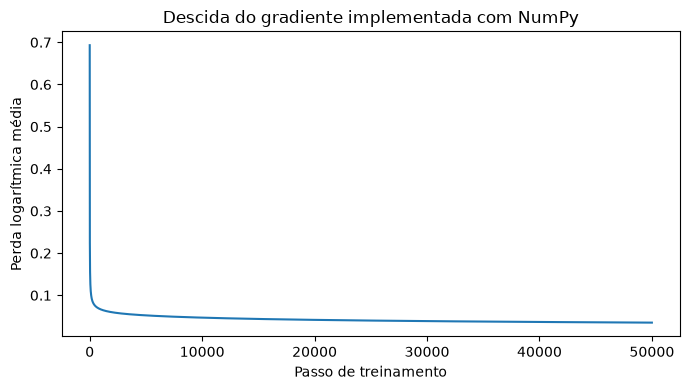

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(history)
plt.xlabel("Passo de treinamento")
plt.ylabel("Perda logarítmica média")
plt.title("Descida do gradiente implementada com NumPy")
plt.tight_layout()
plt.show()

**Explicação linha a linha**

1. Criamos o primeiro gráfico.
2. Desenhamos os valores registrados; a posição na lista é o eixo horizontal.
3–5. Identificamos passos, função objetivo e método de treinamento.
6. Ajustamos as margens automaticamente.
7. Exibimos a figura.

A queda da perda indica que o treinamento está reduzindo o objetivo. Não comprova desempenho em amostras novas: ainda precisamos avaliar o teste.

## 11. Prever probabilidade e decidir classe são operações diferentes

`predict_proba` vai aplicar os parâmetros aprendidos a outras amostras. `predict` vai transformar essas probabilidades em classes. O limiar será **0,5**, escolhido antes de consultar o teste.

A coluna de 1s precisa aparecer também na previsão, para que `theta[0]` continue atuando como intercepto. Ela é acrescentada dentro da função, sem exigir que o usuário a prepare fora.

In [10]:
def predict_proba(X, theta):
    X_b = np.c_[np.ones((X.shape[0], 1)), X]
    return sigmoid(X_b @ theta)


def predict(X, theta, threshold=0.5):
    return (predict_proba(X, theta) >= threshold).astype(int)

**Explicação linha a linha**

1. `predict_proba` recebe medidas já padronizadas e o vetor aprendido.
2. Acrescenta uma coluna inicial de 1s às amostras recebidas.
3. Calcula escores e aplica a sigmoide. Retorna **um vetor** com a probabilidade de maligno para cada linha. Não há atualização de parâmetros.
4. `predict` define uma segunda função com um limiar configurável.
5. A comparação `>= threshold` retorna verdadeiro/falso; `astype(int)` converte para 1/0. No caso de probabilidade exatamente igual ao corte, a classe será 1.

Nossa função retorna um vetor de probabilidades da classe 1. A função do scikit-learn retorna uma matriz com duas colunas; selecionaremos a segunda para comparar o mesmo evento.

## 12. Avaliar o modelo manual

A acurácia é a fração de decisões corretas. Vamos mostrá-la no treino e no teste, além de contar os dois tipos de erro no teste. Os rótulos usados para avaliar o teste não participaram de nenhum ajuste.

In [11]:
y_pred_train = predict(X_train_scaled, theta_hat)
y_pred_test = predict(X_test_scaled, theta_hat)
print("Acurácia no treino:", accuracy_score(y_train, y_pred_train))
print("Acurácia no teste:", accuracy_score(y_test, y_pred_test))
print("Falsos negativos no teste:", np.sum((y_test == 1) & (y_pred_test == 0)))
print("Falsos positivos no teste:", np.sum((y_test == 0) & (y_pred_test == 1)))

Acurácia no treino: 0.9868131868131869
Acurácia no teste: 0.9736842105263158
Falsos negativos no teste: 3
Falsos positivos no teste: 0


**Explicação linha a linha**

1. Aplicamos os parâmetros nas medidas de treino para calcular as decisões.
2. Aplicamos os mesmos parâmetros nas medidas de teste, mantendo o corte 0,5.
3. `accuracy_score` compara respostas reais e previstas no treino e calcula a fração de acertos.
4. Repetimos essa medida no teste reservado.
5. Um falso negativo é um maligno real previsto como benigno. `&` exige as duas condições ao mesmo tempo; `sum` conta os casos. Os parênteses preservam a ordem correta das operações.
6. Um falso positivo é um benigno real previsto como maligno.

Treino e teste podem ter resultados diferentes. Uma acurácia alta não descreve sozinha o tipo dos erros nem demonstra generalização para outras populações.

## 13. Comparar com scikit-learn

Usaremos a mesma preparação, as mesmas amostras, o mesmo limiar e o mesmo objetivo **sem regularização**. Neste ambiente, `C=np.inf` desativa a regularização em `LogisticRegression`.

O `fit` aprende o intercepto automaticamente: **não passamos uma coluna de 1s ao scikit-learn**.

A biblioteca usa L-BFGS por padrão, enquanto nossa implementação usa descida do gradiente. Os caminhos de otimização e os critérios de parada são diferentes. Sem regularização, a aproximação pode ser lenta e, se os dados forem separáveis, os parâmetros podem crescer sem um mínimo finito. Por isso não devemos prometer probabilidades ou pesos iguais apenas porque a fórmula da perda é a mesma.

Vamos comparar os resultados obtidos por cada procedimento e conferir se a execução manual atingiu a tolerância. Diferenças de resultado não significam automaticamente um erro na fórmula; também precisamos considerar a otimização.

In [12]:
model = LogisticRegression(C=np.inf, max_iter=2000, tol=1e-10)
model.fit(X_train_scaled, y_train)
p_manual = predict_proba(X_test_scaled, theta_hat)
p_sklearn = model.predict_proba(X_test_scaled)[:, 1]
y_sklearn = (p_sklearn >= 0.5).astype(int)
print("Ordem das classes no scikit-learn:", model.classes_)
print("Maior diferença nas probabilidades:", np.max(np.abs(p_manual - p_sklearn)))

Ordem das classes no scikit-learn: [0 1]
Maior diferença nas probabilidades: 0.4866124568867905


**Explicação linha a linha**

1. Criamos `LogisticRegression(C=np.inf, ...)`, sem regularização no scikit-learn instalado. `max_iter` limita os passos de L-BFGS e `tol` configura seu critério interno de convergência; não é necessariamente o mesmo critério da nossa função.
2. `fit` treina com as mesmas medidas padronizadas e respostas. Não há outra divisão nem recálculo de médias e desvios.
3. Nossa função retorna a probabilidade de maligno para cada amostra do teste.
4. O scikit-learn retorna duas colunas. `[:, 1]` seleciona todas as linhas da segunda coluna, correspondente à classe 1.
5. Aplicamos o mesmo corte 0,5 às probabilidades da biblioteca.
6. Conferimos a ordem `[0, 1]` das classes.
7. Subtraímos as probabilidades, usamos `abs` para obter diferenças absolutas e `max` para mostrar a maior delas.

Probabilidades diferentes podem resultar tanto em decisões iguais quanto diferentes. Nesta comparação, ambos minimizam a mesma perda, mas não impomos que tenham chegado ao mesmo ponto em um número finito de passos. O teste apenas descreve esses resultados: não será usado para escolher o número de passos nem para favorecer uma implementação.

In [13]:
comparacao = pd.DataFrame({
    "Modelo": ["NumPy", "scikit-learn"],
    "Acurácia treino": [accuracy_score(y_train, y_pred_train), accuracy_score(y_train, model.predict(X_train_scaled))],
    "Acurácia teste": [accuracy_score(y_test, y_pred_test), accuracy_score(y_test, y_sklearn)],
    "Falsos negativos": [np.sum((y_test == 1) & (y_pred_test == 0)), np.sum((y_test == 1) & (y_sklearn == 0))],
    "Falsos positivos": [np.sum((y_test == 0) & (y_pred_test == 1)), np.sum((y_test == 0) & (y_sklearn == 1))],
})
comparacao.round(4)

,Modelo,Acurácia treino,Acurácia teste,Falsos negativos,Falsos positivos
0,NumPy,0.9868,0.9737,3,0
1,scikit-learn,1.0000,0.9737,3,0


**Explicação linha a linha**

- `DataFrame` organiza uma linha por implementação.
- A primeira coluna contém os nomes dos modelos.
- As duas seguintes comparam acurácia de treino e de teste. O `model.predict` da biblioteca usa a decisão padrão no treino; nas probabilidades exatamente empatadas em 0,5 a biblioteca pode decidir pela primeira classe, mas nesta execução não há empates.
- As últimas duas colunas contam os erros do teste, com a mesma definição para ambos.
- Cada lista contém primeiro o resultado manual e depois o da biblioteca.
- `round(4)` muda apenas a apresentação da tabela, não os cálculos.

Essa comparação usa configurações previamente fixadas. Não vamos escolher um limiar ou uma taxa diferente depois de olhar o teste e continuar chamando-o de uma avaliação independente.

**Como interpretar a comparação:** confira o indicador de tolerância do treinamento manual e a diferença entre as probabilidades. Sem regularização, a descida do gradiente pode chegar ao limite de passos antes de atingir a tolerância. Em dados separáveis, o objetivo pode se aproximar de zero com pesos cada vez maiores, sem mínimo em parâmetros finitos. Assim, o mesmo objetivo não garante os mesmos parâmetros ou probabilidades em dois procedimentos de otimização com critérios de parada diferentes.

Uma acurácia maior nesta única divisão não prova superioridade geral de uma implementação. Os valores da tabela correspondem à divisão atual, feita com NumPy, e não à divisão das versões anteriores.

## 14. Segundo e último gráfico: olhar probabilidades de dez amostras

Como usamos 30 entradas, não há uma única curva em função de uma delas sem fixar o que acontece com as outras 29. Vamos comparar probabilidades em dez amostras e marcar o limiar.

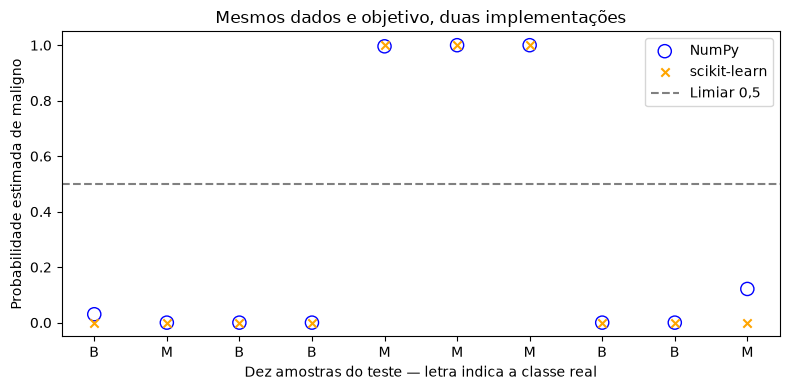

In [14]:
plt.figure(figsize=(8, 4))
plt.scatter(range(10), p_manual[:10], label="NumPy", s=90, facecolors="none", edgecolors="blue")
plt.scatter(range(10), p_sklearn[:10], label="scikit-learn", marker="x", color="orange")
plt.axhline(0.5, color="gray", linestyle="--", label="Limiar 0,5")
plt.xticks(range(10), ["M" if classe == 1 else "B" for classe in y_test[:10]])
plt.xlabel("Dez amostras do teste — letra indica a classe real")
plt.ylabel("Probabilidade estimada de maligno")
plt.title("Mesmos dados e objetivo, duas implementações")
plt.legend()
plt.tight_layout()
plt.show()

**Explicação linha a linha**

1. Abrimos a segunda figura do notebook.
2. Desenhamos as probabilidades manuais das primeiras dez amostras em posições de 0 a 9. Os círculos vazios permitem ver marcadores sobrepostos.
3. Desenhamos as probabilidades do scikit-learn nas mesmas posições, com marcadores em X.
4. A linha horizontal marca o corte 0,5.
5. Trocamos os números do eixo horizontal pelas classes reais M/B. A compreensão de lista escolhe a letra de cada resposta conhecida. Letras repetidas continuam representando amostras diferentes.
6–8. Explicamos os eixos e damos um título. O eixo horizontal é uma lista de amostras, não uma medida celular.
9–11. Exibimos a legenda, ajustamos margens e mostramos a figura.

Uma amostra M com probabilidade abaixo do corte é um falso negativo. Uma amostra B acima do corte é um falso positivo. Probabilidade não é certeza, e sua calibração não foi avaliada neste notebook.

## 15. Relação entre fórmulas e código

$$\text{entradas}\ \xrightarrow{\,X_b\theta\,}\ \text{escore}\ \xrightarrow{\,\sigma\,}\ \text{probabilidade}\ \xrightarrow{\,\text{limiar}\,}\ \text{classe}.$$

| Conceito | Onde aparece |
|---|---|
| Intercepto e 30 pesos | `theta[0]` e `theta[1:]` |
| Matriz com intercepto | `np.c_[np.ones((X.shape[0], 1)), X]` |
| Combinação linear | `X_b @ theta` |
| Probabilidade de maligno | `sigmoid(X_b @ theta)` |
| Gradiente dos dados | `X_b.T @ (p - y) / m` |
| Atualização dos parâmetros | `theta -= alpha * grad` |
| Decisão | `predict_proba(X, theta) >= threshold` |

**Interpretação dos conceitos:**

1. **Por que são 31 parâmetros para 30 medidas?** Há um intercepto além dos 30 pesos; a coluna de 1s permite tratá-los no mesmo produto matricial.
2. **Por que o gradiente contém `p - y`?** A regra da cadeia cancela os termos da derivada da perda e da sigmoide, restando essa diferença.
3. **Por que subtrair o gradiente?** Ele aponta para crescimento local da perda; queremos caminhar no sentido contrário.
4. **Por que usar `X_b` no gradiente?** Porque o vetor de parâmetros contém o intercepto e precisa da contribuição da coluna de 1s.
5. **Por que reutilizar média e desvio do treino no teste?** Para aplicar a transformação aprendida sem fazer o teste influenciar a preparação. Uma amostra nova deve receber exatamente o mesmo tratamento antes da previsão.
6. **Por que os resultados podem diferir mesmo com a mesma perda?** Os otimizadores usam caminhos e critérios de parada diferentes. Um número finito de passos não garante atingir o mesmo ponto, e dados separáveis podem não ter um mínimo em parâmetros finitos.
7. **Baixar o limiar muda os pesos?** Não. Muda só a decisão a partir das mesmas probabilidades. Nos mesmos dados, pode aumentar positivos previstos e falsos positivos, enquanto falsos negativos não aumentam.
8. **Um peso grande prova uma causa?** Não. É uma associação condicional no modelo; várias medidas desta base são correlacionadas.

**Limites do exercício:** usamos uma única divisão pequena. Resultados altos aqui não garantem desempenho em outros locais ou populações. Uma avaliação mais ampla envolve validação cruzada, seleção de hiperparâmetros dentro do desenvolvimento, análise de incerteza, calibração e validação externa.

### Referências

- [UCI — Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic): origem da base e descrição das medidas.
- [scikit-learn — regressão logística e função objetivo](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression).
- [scikit-learn — LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [NumPy — gerador aleatório e permutação](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.permutation.html).
- [NumPy — média](https://numpy.org/doc/stable/reference/generated/numpy.mean.html) e [desvio padrão](https://numpy.org/doc/stable/reference/generated/numpy.std.html).

**Convenção dos rótulos:** o CSV foi mapeado explicitamente como M=1 e B=0. O carregador `load_breast_cancer` usa a convenção oposta, por isso não substitua a fonte sem conferir esse detalhe.